In [1]:

import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


model_path = r"D:\projects\supply chain project\models\xgboost_supply_chain_model.joblib"


model_artifacts = joblib.load(model_path)

xgb_model = model_artifacts['model']
preprocessor = model_artifacts['preprocessor']
chosen_threshold = model_artifacts['threshold']

print("Model artifacts loaded successfully!")
print("Model:", type(xgb_model).__name__)
print("Preprocessor:", type(preprocessor).__name__)
print("Selected threshold:", chosen_threshold)


Model artifacts loaded successfully!
Model: XGBClassifier
Preprocessor: ColumnTransformer
Selected threshold: 0.35


In [2]:


data_path = r"D:\projects\supply chain project\datasets\processed\DataCoSupplyChain_ML_ready.csv"

df = pd.read_csv(data_path)


X = df.drop(columns=['Late_delivery_risk'])
y = df['Late_delivery_risk']


print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Number of shipments:", len(df))
print("Number of input features:", X.shape[1])
print("Target column:", 'Late_delivery_risk')

display(df.head())


Dataset loaded successfully!
Dataset shape: (180519, 23)
Number of shipments: 180519
Number of input features: 22
Target column: Late_delivery_risk


,Days for shipment (scheduled),Order Item Discount,Order Item Quantity,Sales,Product Price,Latitude,Longitude,Type,Customer Country,Customer Segment,...,Order Country,Category Id,Product Card Id,Department Id,Order Year,Order Month,Order Day,Order Day of Week,Order Hour,Late_delivery_risk
0,4,13.110000,1,327.75,327.75,18.251453,-66.037056,DEBIT,Puerto Rico,Consumer,...,Indonesia,73,1360,2,2018,1,31,2,22,0
1,4,16.389999,1,327.75,327.75,18.279451,-66.037064,TRANSFER,Puerto Rico,Consumer,...,India,73,1360,2,2018,1,13,5,12,1
2,4,18.030001,1,327.75,327.75,37.292233,-121.881279,CASH,EE. UU.,Consumer,...,India,73,1360,2,2018,1,13,5,12,0
3,4,22.940001,1,327.75,327.75,34.125946,-118.291016,DEBIT,EE. UU.,Home Office,...,Australia,73,1360,2,2018,1,13,5,11,0
4,4,29.500000,1,327.75,327.75,18.253769,-66.037048,PAYMENT,Puerto Rico,Corporate,...,Australia,73,1360,2,2018,1,13,5,11,0


In [3]:


X_processed = preprocessor.transform(X)

print("Processed data shape:", X_processed.shape)


risk_probabilities = xgb_model.predict_proba(X_processed)[:, 1]


risk_df = df.copy()
risk_df['Late_Delivery_Probability'] = risk_probabilities


risk_df['Predicted_Late_Risk'] = (
    risk_df['Late_Delivery_Probability'] >= chosen_threshold
).astype(int)

print("\nRisk probabilities generated successfully!")
print("Number of shipments scored:", len(risk_df))
print("\nFirst 5 predictions:")

display(
    risk_df[
        ['Late_Delivery_Probability', 'Predicted_Late_Risk']
    ].head()
)


Processed data shape: (180519, 427)

Risk probabilities generated successfully!
Number of shipments scored: 180519

First 5 predictions:


,Late_Delivery_Probability,Predicted_Late_Risk
0,0.370796,1
1,0.341636,0
2,0.391743,1
3,0.402578,1
4,0.377293,1


In [4]:


def assign_risk_category(probability):
    if probability >= 0.70:
        return 'High Risk'
    elif probability >= chosen_threshold:
        return 'Medium Risk'
    else:
        return 'Low Risk'

risk_df['Risk_Category'] = (
    risk_df['Late_Delivery_Probability']
    .apply(assign_risk_category)
)


display(
    risk_df[
        [
            'Late_Delivery_Probability',
            'Predicted_Late_Risk',
            'Risk_Category'
        ]
    ].head(10)
)


print("\nRisk category counts:")
display(
    risk_df['Risk_Category']
    .value_counts()
    .rename_axis('Risk Category')
    .reset_index(name='Number of Shipments')
)


,Late_Delivery_Probability,Predicted_Late_Risk,Risk_Category
0,0.370796,1,Medium Risk
1,0.341636,0,Low Risk
2,0.391743,1,Medium Risk
3,0.402578,1,Medium Risk
4,0.377293,1,Medium Risk
5,0.314413,0,Low Risk
6,0.997956,1,High Risk
7,0.547383,1,Medium Risk
8,0.819459,1,High Risk
9,0.997778,1,High Risk



Risk category counts:


,Risk Category,Number of Shipments
0,Medium Risk,89924
1,High Risk,60816
2,Low Risk,29779


In [5]:


risk_counts = (
    risk_df['Risk_Category']
    .value_counts()
    .reindex(['High Risk', 'Medium Risk', 'Low Risk'], fill_value=0)
)


risk_percentages = (risk_counts / len(risk_df) * 100).round(2)


risk_summary = pd.DataFrame({
    'Risk Category': risk_counts.index,
    'Number of Shipments': risk_counts.values,
    'Percentage (%)': risk_percentages.values
})

display(risk_summary)

print("Total shipments:", risk_summary['Number of Shipments'].sum())


,Risk Category,Number of Shipments,Percentage (%)
0,High Risk,60816,33.69
1,Medium Risk,89924,49.81
2,Low Risk,29779,16.50


Total shipments: 180519


In [6]:


risk_df = risk_df.sort_values(
    by='Late_Delivery_Probability',
    ascending=False
).reset_index(drop=True)


risk_df['Priority_Rank'] = range(1, len(risk_df) + 1)

priority_columns = [
    'Priority_Rank',
    'Late_Delivery_Probability',
    'Risk_Category',
    'Predicted_Late_Risk'
]

display(risk_df[priority_columns].head(20))

print("\nTotal ranked shipments:", len(risk_df))


,Priority_Rank,Late_Delivery_Probability,Risk_Category,Predicted_Late_Risk
0,1,0.999092,High Risk,1
1,2,0.999082,High Risk,1
2,3,0.999031,High Risk,1
3,4,0.999029,High Risk,1
4,5,0.999027,High Risk,1
5,6,0.999026,High Risk,1
6,7,0.999026,High Risk,1
7,8,0.999025,High Risk,1
8,9,0.999005,High Risk,1
9,10,0.998961,High Risk,1



Total ranked shipments: 180519


In [7]:


priority_summary = (
    risk_df.groupby('Risk_Category')
    .agg(
        Number_of_Shipments=('Risk_Category', 'count'),
        Average_Risk_Probability=('Late_Delivery_Probability', 'mean'),
        Minimum_Risk_Probability=('Late_Delivery_Probability', 'min'),
        Maximum_Risk_Probability=('Late_Delivery_Probability', 'max')
    )
    .reset_index()
)

priority_summary['Percentage'] = (
    priority_summary['Number_of_Shipments'] / len(risk_df) * 100
).round(2)


priority_order = {
    'High Risk': 0,
    'Medium Risk': 1,
    'Low Risk': 2
}

priority_summary['Sort_Order'] = (
    priority_summary['Risk_Category'].map(priority_order)
)

priority_summary = (
    priority_summary.sort_values('Sort_Order')
    .drop(columns='Sort_Order')
    .reset_index(drop=True)
)


probability_columns = [
    'Average_Risk_Probability',
    'Minimum_Risk_Probability',
    'Maximum_Risk_Probability'
]

priority_summary[probability_columns] = (
    priority_summary[probability_columns].round(4)
)

display(priority_summary)


,Risk_Category,Number_of_Shipments,Average_Risk_Probability,Minimum_Risk_Probability,Maximum_Risk_Probability,Percentage
0,High Risk,60816,0.8763,0.7000,0.9991,33.69
1,Medium Risk,89924,0.4199,0.3500,0.7000,49.81
2,Low Risk,29779,0.2673,0.0021,0.3500,16.50


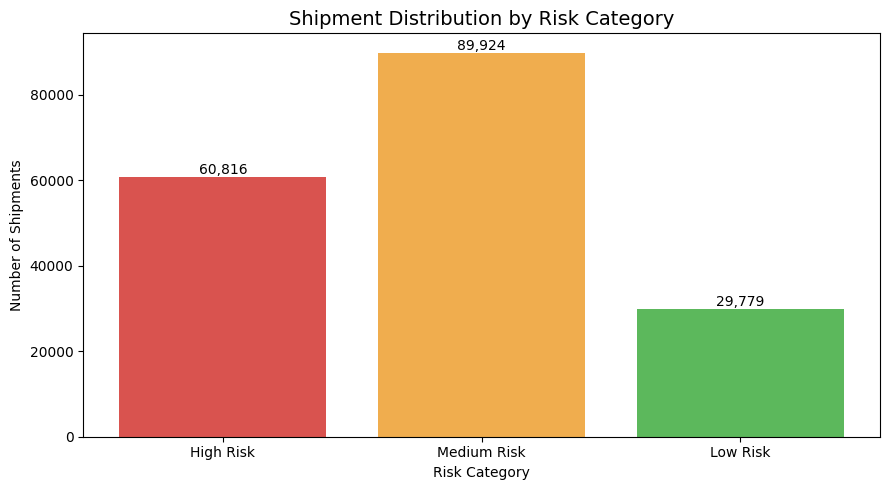

In [8]:

# Plot shipment counts by risk category
risk_counts = (
    risk_df['Risk_Category']
    .value_counts()
    .reindex(['High Risk', 'Medium Risk', 'Low Risk'])
)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    risk_counts.index,
    risk_counts.values,
    color=['#d9534f', '#f0ad4e', '#5cb85c']
)

plt.title('Shipment Distribution by Risk Category', fontsize=14)
plt.xlabel('Risk Category')
plt.ylabel('Number of Shipments')
plt.xticks(rotation=0)

# Display shipment counts above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{int(height):,}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()


In [9]:


df = pd.read_csv(data_path)


X = df.drop(columns=['Late_delivery_risk'])
X_processed = preprocessor.transform(X)

risk_probabilities = xgb_model.predict_proba(X_processed)[:, 1]

risk_df = df.copy()
risk_df['Original_Row_Index'] = np.arange(len(risk_df))
risk_df['Late_Delivery_Probability'] = risk_probabilities

risk_df['Predicted_Late_Risk'] = (
    risk_df['Late_Delivery_Probability'] >= chosen_threshold
).astype(int)


risk_df['Risk_Category'] = np.select(
    [
        risk_df['Late_Delivery_Probability'] >= 0.70,
        risk_df['Late_Delivery_Probability'] >= chosen_threshold
    ],
    ['High Risk', 'Medium Risk'],
    default='Low Risk'
)

risk_df = risk_df.sort_values(
    'Late_Delivery_Probability',
    ascending=False
).reset_index(drop=True)

risk_df['Priority_Rank'] = np.arange(1, len(risk_df) + 1)


priority_columns = [
    'Priority_Rank',
    'Original_Row_Index',
    'Late_Delivery_Probability',
    'Risk_Category',
    'Days for shipment (scheduled)',
    'Order Item Quantity',
    'Sales',
    'Order Region',
    'Type'
]

display(risk_df[priority_columns].head(20))


,Priority_Rank,Original_Row_Index,Late_Delivery_Probability,Risk_Category,Days for shipment (scheduled),Order Item Quantity,Sales,Order Region,Type
0,1,27093,0.999092,High Risk,1,4,239.960007,Central Asia,DEBIT
1,2,27213,0.999082,High Risk,1,5,250.000000,Central Asia,DEBIT
2,3,111973,0.999031,High Risk,1,1,49.980000,Central Africa,PAYMENT
3,4,111481,0.999029,High Risk,1,1,49.980000,Central Asia,CASH
4,5,32943,0.999027,High Risk,1,5,199.949997,Central Asia,CASH
5,6,146264,0.999026,High Risk,1,1,399.980011,Central Africa,PAYMENT
6,7,146265,0.999026,High Risk,1,1,399.980011,Central Africa,PAYMENT
7,8,28616,0.999025,High Risk,1,3,150.000000,Central Africa,PAYMENT
8,9,28807,0.999005,High Risk,1,5,499.950012,Central Africa,PAYMENT
9,10,145918,0.998961,High Risk,1,1,399.980011,Northern Europe,PAYMENT


,Order Region,High_Risk_Shipments,Average_Risk_Probability
22,Western Europe,9544,0.8791
3,Central America,9463,0.8708
12,South America,4891,0.8722
15,Southeast Asia,3260,0.8787
11,Oceania,3249,0.8664
17,Southern Europe,3229,0.8859
10,Northern Europe,3226,0.8736
13,South Asia,2763,0.8796
1,Caribbean,2701,0.8746
21,West of USA,2587,0.8706


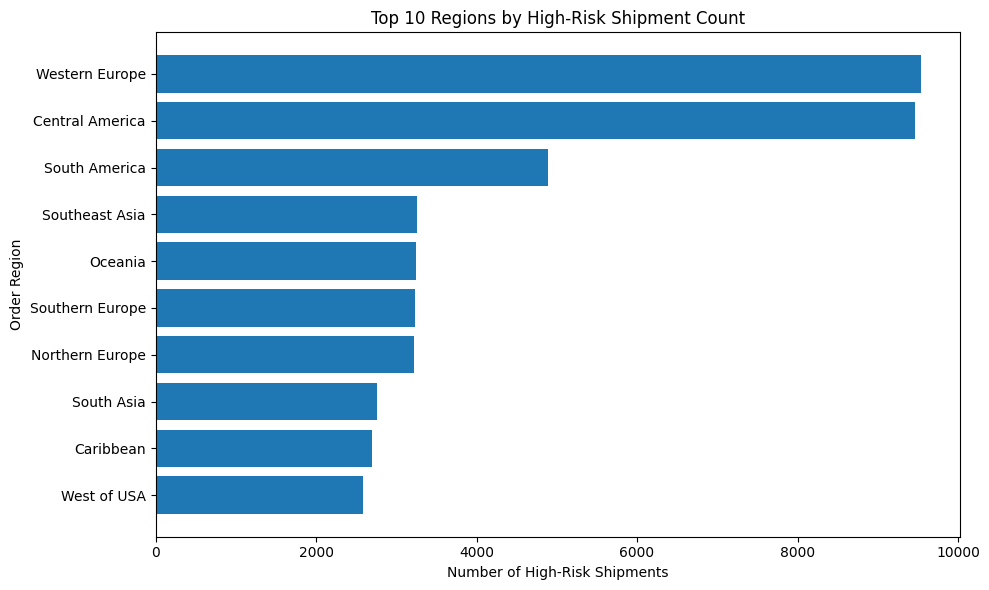

In [10]:

# Filter high-risk shipments
high_risk_df = risk_df[
    risk_df['Risk_Category'] == 'High Risk'
].copy()

# Summarize high-risk shipments by region
region_risk_summary = (
    high_risk_df.groupby('Order Region')
    .agg(
        High_Risk_Shipments=('Risk_Category', 'count'),
        Average_Risk_Probability=('Late_Delivery_Probability', 'mean')
    )
    .reset_index()
    .sort_values(
        'High_Risk_Shipments',
        ascending=False
    )
)

region_risk_summary['Average_Risk_Probability'] = (
    region_risk_summary['Average_Risk_Probability'].round(4)
)

display(region_risk_summary.head(10))

# Visualize the top 10 regions by high-risk shipment count
top_regions = region_risk_summary.head(10).sort_values(
    'High_Risk_Shipments',
    ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_regions['Order Region'],
    top_regions['High_Risk_Shipments']
)
plt.title('Top 10 Regions by High-Risk Shipment Count')
plt.xlabel('Number of High-Risk Shipments')
plt.ylabel('Order Region')
plt.tight_layout()
plt.show()


,Order Region,Total_Shipments,High_Risk_Shipments,High_Risk_Rate_Percent
0,South of USA,4045,1482,36.64
1,South Asia,7731,2763,35.74
2,Western Europe,27109,9544,35.21
3,US Center,5887,2037,34.60
4,Central Africa,1677,578,34.47
5,Eastern Europe,3920,1346,34.34
6,Southern Europe,9431,3229,34.24
7,Southeast Asia,9539,3260,34.18
8,West Africa,3696,1262,34.15
9,West Asia,6009,2049,34.10


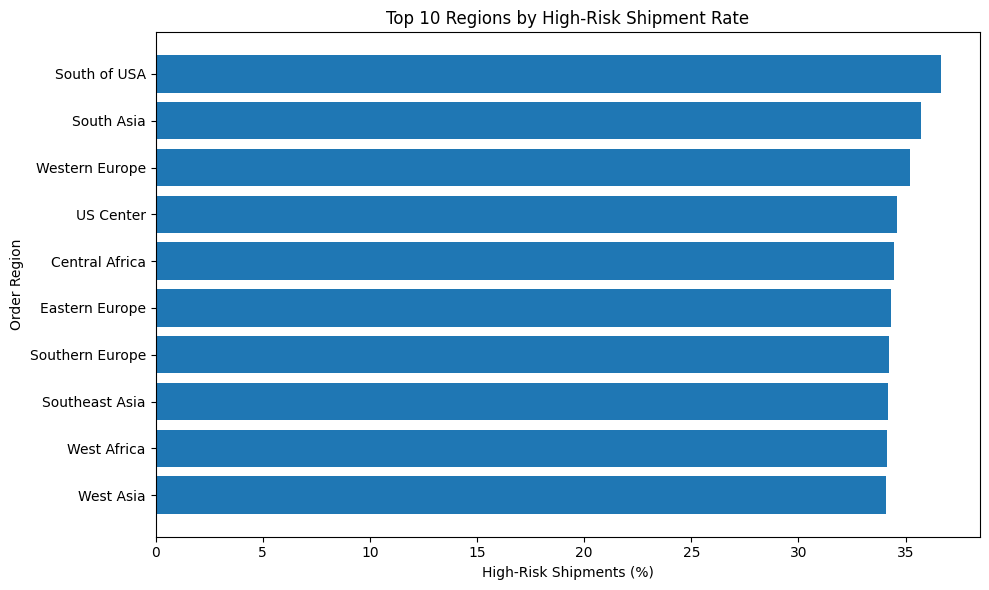

In [11]:


regional_summary = (
    risk_df.groupby('Order Region')
    .agg(
        Total_Shipments=('Risk_Category', 'count'),
        High_Risk_Shipments=(
            'Risk_Category',
            lambda values: (values == 'High Risk').sum()
        )
    )
    .reset_index()
)


regional_summary['High_Risk_Rate_Percent'] = (
    regional_summary['High_Risk_Shipments']
    / regional_summary['Total_Shipments'] * 100
).round(2)


regional_summary = regional_summary.sort_values(
    'High_Risk_Rate_Percent',
    ascending=False
).reset_index(drop=True)

display(regional_summary.head(10))


top_risk_rate_regions = regional_summary.head(10).sort_values(
    'High_Risk_Rate_Percent',
    ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_risk_rate_regions['Order Region'],
    top_risk_rate_regions['High_Risk_Rate_Percent']
)
plt.title('Top 10 Regions by High-Risk Shipment Rate')
plt.xlabel('High-Risk Shipments (%)')
plt.ylabel('Order Region')
plt.tight_layout()
plt.show()


,Type,Total_Shipments,High_Risk_Shipments,Average_Risk_Probability,High_Risk_Rate_Percent
0,CASH,19616,7333,0.5710,37.38
1,PAYMENT,41725,15591,0.5741,37.37
2,DEBIT,69295,25801,0.5708,37.23
3,TRANSFER,49883,12091,0.4873,24.24


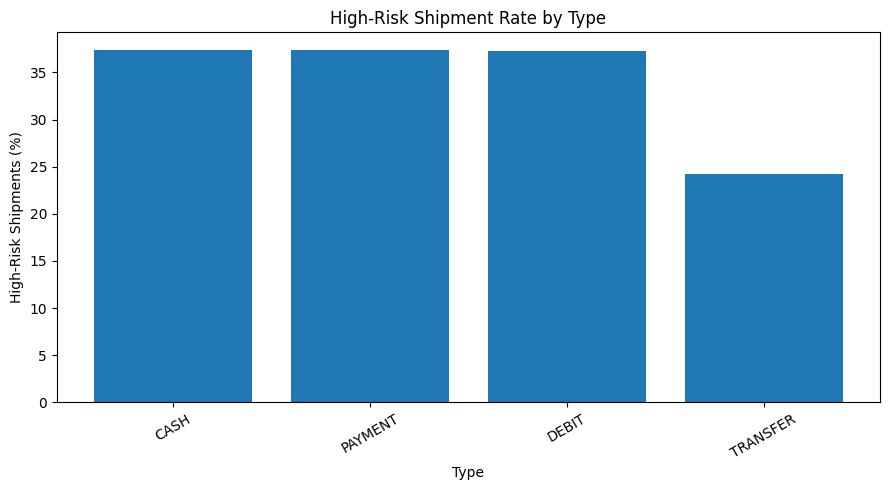

In [12]:


type_risk_summary = (
    risk_df.groupby('Type')
    .agg(
        Total_Shipments=('Risk_Category', 'count'),
        High_Risk_Shipments=(
            'Risk_Category',
            lambda values: (values == 'High Risk').sum()
        ),
        Average_Risk_Probability=(
            'Late_Delivery_Probability', 'mean'
        )
    )
    .reset_index()
)


type_risk_summary['High_Risk_Rate_Percent'] = (
    type_risk_summary['High_Risk_Shipments']
    / type_risk_summary['Total_Shipments'] * 100
).round(2)

type_risk_summary['Average_Risk_Probability'] = (
    type_risk_summary['Average_Risk_Probability'].round(4)
)

type_risk_summary = type_risk_summary.sort_values(
    'High_Risk_Rate_Percent',
    ascending=False
).reset_index(drop=True)

display(type_risk_summary)


plt.figure(figsize=(9, 5))
plt.bar(
    type_risk_summary['Type'],
    type_risk_summary['High_Risk_Rate_Percent']
)
plt.title('High-Risk Shipment Rate by Type')
plt.xlabel('Type')
plt.ylabel('High-Risk Shipments (%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [13]:

# Define the output folder
output_folder = r"D:\projects\supply chain project\reports"
os.makedirs(output_folder, exist_ok=True)

# Export the complete ranked shipment report
shipment_report_path = os.path.join(
    output_folder,
    "shipment_risk_priority_report.csv"
)

risk_df.to_csv(shipment_report_path, index=False)

# Export regional high-risk analysis
regional_report_path = os.path.join(
    output_folder,
    "regional_risk_analysis.csv"
)

regional_summary.to_csv(regional_report_path, index=False)

# Export risk summary by shipment type
type_report_path = os.path.join(
    output_folder,
    "shipment_type_risk_analysis.csv"
)

type_risk_summary.to_csv(type_report_path, index=False)

print("Risk reports exported successfully!")
print("\nSaved files:")
print(shipment_report_path)
print(regional_report_path)
print(type_report_path)


Risk reports exported successfully!

Saved files:
D:\projects\supply chain project\reports\shipment_risk_priority_report.csv
D:\projects\supply chain project\reports\regional_risk_analysis.csv
D:\projects\supply chain project\reports\shipment_type_risk_analysis.csv
